# Diabetes Readmission Prediction
## Random Forest Analysis - Drew Dean

### Objective
Analyze diabetes patient readmission rates and investigate
whether patient and hospital encounter characteristics can
predict readmission within 30 days.

In [22]:
#Imports and load the data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv('../Data/diabetic_data.csv')

## Intial Impressions
Here I investigate aspects of the dataset.  
Observations:  
    -There is only 11.16% of patients readmitted within 30 days. This means that the dataset is very imbalanced so I will have account for that when
    training  
    -weight, max_glu_serum, and A1Cresult all have more than 50% missing values. Their importance will have to be evaluated in the data preperation stage.      

In [23]:

#Replace all ? with nan so that Pandas recognizes it as a missing value
df.replace('?', np.nan, inplace=True)

#Total Readmitted within 30 days
readmitted_30 = (df['readmitted'] == '<30').sum()

#Percent Readmitted within 30 days
total_encounters = len(df)
readmission_percentage = (readmitted_30 / total_encounters) * 100

print("Readmitted within 30 days:", readmitted_30)
print(f"Percentage readmitted within 30 days: {readmission_percentage:.2f}%")

#Distribution
df['readmitted'].value_counts()

Readmitted within 30 days: 11357
Percentage readmitted within 30 days: 11.16%


readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

In [24]:
#Look for missing values

#Make a summary dataframe
missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage Missing': (df.isnull().sum() / len(df)) * 100
})

#Only values where there is more than 0
missing_summary = missing_summary[missing_summary['Missing Values'] > 0]

print(missing_summary.sort_values(by='Percentage Missing', ascending=False))

                   Missing Values  Percentage Missing
weight                      98569           96.858479
max_glu_serum               96420           94.746772
A1Cresult                   84748           83.277322
medical_specialty           49949           49.082208
payer_code                  40256           39.557416
race                         2273            2.233555
diag_3                       1423            1.398306
diag_2                        358            0.351787
diag_1                         21            0.020636


In [25]:
#Info about the features
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

In [26]:
df.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


## Data Preperation
Here I prep the data for training.  

First I examined features that should be dropped from consideration.  

-I dropped weight because it has 97% of its data missing. Replacing it would require so much inference that the data would not be very helpful.    
-Payment Info and Encounter ID were dropped because they seemed irrelavent for determining the target. I figured that payment information wasn't gonna be an indicator of treatment and encounter id just identifies each patient encounter.    

-I kept A1C, glucose, and medical speciality even though they have a lot of missing data. This is because these relate directly to the patients treatment, meaning it seems like it could be a helpful determining factor in the target. I replaced the missing values with "Unkown". These values being unkown in itself could be a helpful determining factor. 

And lastly, under discharge disposition, I've chosen to exclude codes where the patient passed away. This is because a patient who is expired cannot be readmitted to the hosptial, so in this case their data is would be noise.

In [27]:
#Dropping features
columns_to_drop = [
    'weight', 'payer_code', 'encounter_id'
]
df = df.drop(columns=columns_to_drop)

# Replace missing values with "Unknown".
columns_to_fill = [
    'max_glu_serum',
    'A1Cresult',
    'medical_specialty',
    'race',
    'diag_1',
    'diag_2',
    'diag_3'
]

df[columns_to_fill] = df[columns_to_fill].fillna('Unknown')

# Exclude patients who died.
df = df[~df['discharge_disposition_id'].isin([11, 19, 20, 21])]

# Since were testing for readmittance within 30 days, I convert readmitted into a binary value:
# 1 = Readmitted within 30 days
# 0 = Not readmitted within 30 days
df['readmitted'] = (df['readmitted'] == '<30').astype(int)

# Here I seperate the data. X contains all columns except readmitted ( because this is the training data, so having the target would make results invalid)
# In X I also exclude patient_nbr because it is an id to identify patients, making it just noise during training
# Y is the target column, readmitted
# I create a series of just patient ID's so that I can use group splitting later to ensure that the same patient doesn't end up in testing and training data
X = df.drop(columns=['readmitted', 'patient_nbr'])
y = df['readmitted']
groups = df['patient_nbr']

# Double check for any leftover missing values.
print(df.isnull().sum()[df.isnull().sum() > 0])

# Check dimensions.
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Groups shape:", groups.shape)


Series([], dtype: int64)
X shape: (100114, 45)
y shape: (100114,)
Groups shape: (100114,)


In [28]:
#Check the final features for training
for col in df.columns:
    print(col)

patient_nbr
race
gender
age
admission_type_id
discharge_disposition_id
admission_source_id
time_in_hospital
medical_specialty
num_lab_procedures
num_procedures
num_medications
number_outpatient
number_emergency
number_inpatient
diag_1
diag_2
diag_3
number_diagnoses
max_glu_serum
A1Cresult
metformin
repaglinide
nateglinide
chlorpropamide
glimepiride
acetohexamide
glipizide
glyburide
tolbutamide
pioglitazone
rosiglitazone
acarbose
miglitol
troglitazone
tolazamide
examide
citoglipton
insulin
glyburide-metformin
glipizide-metformin
glimepiride-pioglitazone
metformin-rosiglitazone
metformin-pioglitazone
change
diabetesMed
readmitted


### Data Preperation Continued 

In this step, I split up the dataset into a 60/20/20 split (Training, validation, and testing). I do this so that when tuning the model, I'm not tuning the model to the testing data. If I was tuning it to the testing data then I'm not really training predictive power but rather its ability to match this small portion of the data. By intially tuning to a validation set, and then for the final test, testing on the test set, that shows the real predicative capabilities of the model. 

I used group-based splitting from sklearn. This method considers groups when splitting, keeping instances of multiple patient encounters together. 

In [29]:
from sklearn.model_selection import GroupShuffleSplit

# First Split of the Data

#Parameters: splits one time, 80/20, and makes the randomness reproducible
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

#Splits the data
#train_val_idx is the indices for the training
#test_idx is the indices for the testing
train_val_idx, test_idx = next(
    splitter.split(X, y, groups)
)

# Assigns the rows
#X_train_val is the training data
#y_train_val is the "answers" used for training
X_train_val = X.iloc[train_val_idx]
y_train_val = y.iloc[train_val_idx]
groups_train_val = groups.iloc[train_val_idx]

#x_test is the set of predictors used in testing
#y_test is the final set of answers to evaluate the final accuraccy
X_test = X.iloc[test_idx]
y_test = y.iloc[test_idx]
groups_test = groups.iloc[test_idx]


# Second split, take 25% off training data, leaving overall a 60/20/20 distribution
splitter_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, val_idx = next(
    splitter_val.split(X_train_val, y_train_val, groups_train_val)
)

# Final datasets
# Takes the 75/25 split and assigns it to the final training set and validation set, testing set was already made previously
X_train = X_train_val.iloc[train_idx]
y_train = y_train_val.iloc[train_idx]

X_val = X_train_val.iloc[val_idx]
y_val = y_train_val.iloc[val_idx]

# So now we have 60% training data, 20% validation data, and 20% testing data


#Make sure split went correctly

# Check dimensions
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

# Checking for no patient overlap
train_patients = set(groups.iloc[train_val_idx].iloc[train_idx])
val_patients = set(groups_train_val.iloc[val_idx])
test_patients = set(groups_test)

print("Train/Validation overlap:", len(train_patients & val_patients))
print("Train/Test overlap:", len(train_patients & test_patients))
print("Validation/Test overlap:", len(val_patients & test_patients))

#Check to make sure that the target variable, readmitted, is fairly evenly distributed between the sets

print("\nTraining:")
print(y_train.value_counts(normalize=True) * 100)

print("\nValidation:")
print(y_val.value_counts(normalize=True) * 100)

print("\nTesting:")
print(y_test.value_counts(normalize=True) * 100)

Training: (59964, 45)
Validation: (20075, 45)
Testing: (20075, 45)
Train/Validation overlap: 0
Train/Test overlap: 0
Validation/Test overlap: 0

Training:
readmitted
0    88.778267
1    11.221733
Name: proportion, dtype: float64

Validation:
readmitted
0    88.428394
1    11.571606
Name: proportion, dtype: float64

Testing:
readmitted
0    88.518057
1    11.481943
Name: proportion, dtype: float64


Now I aim to encode the data. First I see what categorical features are included in the dataset  

In [30]:
#Examining the different kinds of features
print(X_train.dtypes.value_counts())

print("\nCategorical columns:")
print(X_train.select_dtypes(include=['object']).columns.tolist())

print("\nNumerical columns:")
print(X_train.select_dtypes(include=['number']).columns.tolist())

str      34
int64    11
Name: count, dtype: int64

Categorical columns:
['race', 'gender', 'age', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']

Numerical columns:
['admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']


C:\Users\flabf\AppData\Local\Temp\ipykernel_11268\1446743401.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(X_train.select_dtypes(include=['object']).columns.tolist())


In [31]:
# Storing the different kinds of features
#ID's are categorical, even though they are numbers, so they still go in the categorical group
categorical_columns = [
    'race', 'gender', 'age', 'admission_type_id',
    'discharge_disposition_id', 'admission_source_id',
    'medical_specialty', 'diag_1', 'diag_2', 'diag_3',
    'max_glu_serum', 'A1Cresult',
    'metformin', 'repaglinide', 'nateglinide',
    'chlorpropamide', 'glimepiride', 'acetohexamide',
    'glipizide', 'glyburide', 'tolbutamide',
    'pioglitazone', 'rosiglitazone', 'acarbose',
    'miglitol', 'troglitazone', 'tolazamide',
    'examide', 'citoglipton', 'insulin',
    'glyburide-metformin', 'glipizide-metformin',
    'glimepiride-pioglitazone', 'metformin-rosiglitazone',
    'metformin-pioglitazone', 'change', 'diabetesMed'
]

# Numerical columns
numerical_columns = [
    'time_in_hospital', 'num_lab_procedures',
    'num_procedures', 'num_medications',
    'number_outpatient', 'number_emergency',
    'number_inpatient', 'number_diagnoses'
]

### Data Preperation Continued  

Now I start encoding. I used mainly one hot encoding which creates a seperate column for each new category. For example if the category is color, and the options are red or blue, it makes a column red and a column blue. Then each column can use binary 0 or 1 values instead of being categorical. 

In the Random Forest Model I opted to use class_weight balanced. This is because when examining the data, the majority does not fall in the "readmitted within 30 days" category. This imbalance means that the model could take the approach of improving accuracy by just favoring the majority class, instead of actually searching for truth (Ex: 9/10 days it didn't rain. Weather could predict a rate of 90% by just assuming it will never rain). By using balanced class weights, the minority class has higher weights than the majority class, helping to alleviate the problem. 

In [32]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

#This uses a ColumnTranformer to process the columns
#Categorical columns get encoded using One Hot Encoding method, unknown values get ignored
#Numerical columns don't recieve any operations
preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'),
         categorical_columns),

        ('numerical', 'passthrough',
         numerical_columns)
    ]
)

#The Random Forest Model pipeline. 
#First, data is preproccessed with the preprocessor I defined
#Then, I configure the RandomForestClassifier
#100 decision trees, random_state to have reproducible randomness, class_weight = balanced explained above
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced'
    ))
])


## Random Forest Model Prediction  

I used the model to generated readmission probabilties when comparied to the validating set. To help fine tune the results, I experimeted with different thresholds. If the readmission probability generated by the forest is above the threshold then it'll produce a 1, 0 otherwise.  
I ran a loop running with different thresholds to determine the best one for the model.

In [33]:
#Fitting the model with our data
model.fit(X_train, y_train)

#Gets the probabtilities of readmission againast the validation set
val_probabilities = model.predict_proba(X_val)[:, 1]

In [34]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

#Array of threshold values to try
thresholds = [0.5, 0.4, 0.3, 0.25, 0.2, 0.15, 0.1]

#Try each threshold and output the resulting metrics
for threshold in thresholds:

    predictions = (val_probabilities >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Accuracy:", round(accuracy_score(y_val, predictions), 3))
    print("Precision:", round(precision_score(y_val, predictions), 3))
    print("Recall:", round(recall_score(y_val, predictions), 3))
    print("F1:", round(f1_score(y_val, predictions), 3))


Threshold: 0.5
Accuracy: 0.883
Precision: 0.453
Recall: 0.037
F1: 0.069

Threshold: 0.4
Accuracy: 0.867
Precision: 0.318
Recall: 0.128
F1: 0.183

Threshold: 0.3
Accuracy: 0.781
Precision: 0.225
Recall: 0.365
F1: 0.278

Threshold: 0.25
Accuracy: 0.681
Precision: 0.185
Recall: 0.514
F1: 0.272

Threshold: 0.2
Accuracy: 0.54
Precision: 0.159
Recall: 0.692
F1: 0.258

Threshold: 0.15
Accuracy: 0.367
Precision: 0.137
Recall: 0.845
F1: 0.236

Threshold: 0.1
Accuracy: 0.218
Precision: 0.125
Recall: 0.956
F1: 0.22


In [35]:

# Get probabilities on new data
test_probabilities = model.predict_proba(X_test)[:, 1]

# Apply selected threshold that was best, in this case 0.3
final_predictions = (test_probabilities >= 0.3).astype(int)

# Final evaluation. Comparing the test probabilities to the test set
print("Accuracy:", accuracy_score(y_test, final_predictions))

print("\nClassification Report:")
print(classification_report(y_test, final_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_predictions))

Accuracy: 0.7772851805728518

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.83      0.87     17770
           1       0.21      0.34      0.26      2305

    accuracy                           0.78     20075
   macro avg       0.56      0.59      0.57     20075
weighted avg       0.83      0.78      0.80     20075


Confusion Matrix:
[[14811  2959]
 [ 1512   793]]


## Concluding Thoughts  

My Random Forest model achieved an overall accuracy of ~77.7%. However, it did show clear limitations in finding readmitted patients. The model achieved a recall of 34% and a precision of 21% for the target. The model correctly identified 793 readmissions but missed 1,512. Compared to a baseline of ~88% (The case where the model only predicts no readmission), my model had less accuracy. However, my model identitfied 793 readmissions while the basecase would not, so the usefullness of the models depends on the neccessity of identifing readmissions versus overall accuracy.  

One factor was that even after balancing the the class weights there was still a clear imbalance with the number of readmissions/non-readmissions. Perhaps with a more robust weight system or an even larger dataset greater results can be achieved.   

I based my best threshold experiment on the best F1 score, however this can be up to the needs of the hospital in regard to what metric they want to maximize (like precision).  

Overall, while the model had some ability to find readmission patterns, its low recall and precision indicate that further improvements would be needed before it could be considered reliable.   

## Visualization
Here I made some visualizations for the report

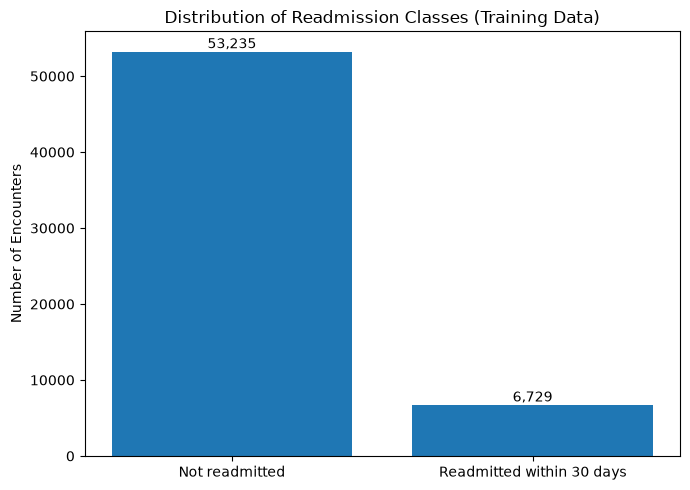

In [36]:
from sklearn.metrics import ConfusionMatrixDisplay

labels = ['Not readmitted', 'Readmitted within 30 days']

counts = y_train.value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(labels, counts.values)

plt.title('Distribution of Readmission Classes (Training Data)')
plt.ylabel('Number of Encounters')

for i, count in enumerate(counts.values):
    plt.text(i, count, f'{count:,}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

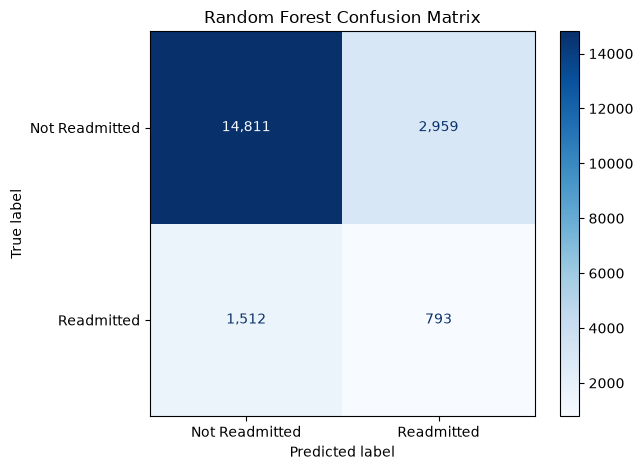

In [37]:
cm = confusion_matrix(y_test, final_predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Readmitted', 'Readmitted']
)

display.plot(values_format=',', cmap='Blues')

plt.title('Random Forest Confusion Matrix')
plt.tight_layout()
plt.show()

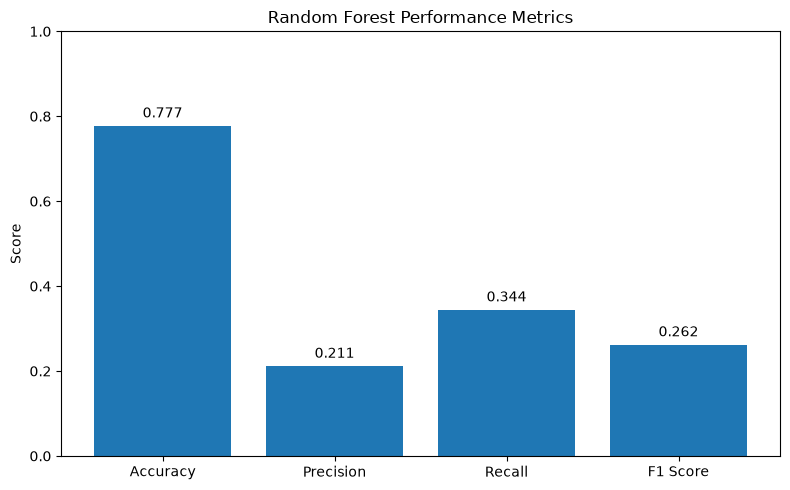

In [38]:
metrics = {
    'Accuracy': accuracy_score(y_test, final_predictions),
    'Precision': precision_score(y_test, final_predictions),
    'Recall': recall_score(y_test, final_predictions),
    'F1 Score': f1_score(y_test, final_predictions)
}

plt.figure(figsize=(8, 5))

bars = plt.bar(metrics.keys(), metrics.values())

plt.title('Random Forest Performance Metrics')
plt.ylabel('Score')
plt.ylim(0, 1)

for bar, value in zip(bars, metrics.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f'{value:.3f}',
        ha='center'
    )

plt.tight_layout()
plt.show()

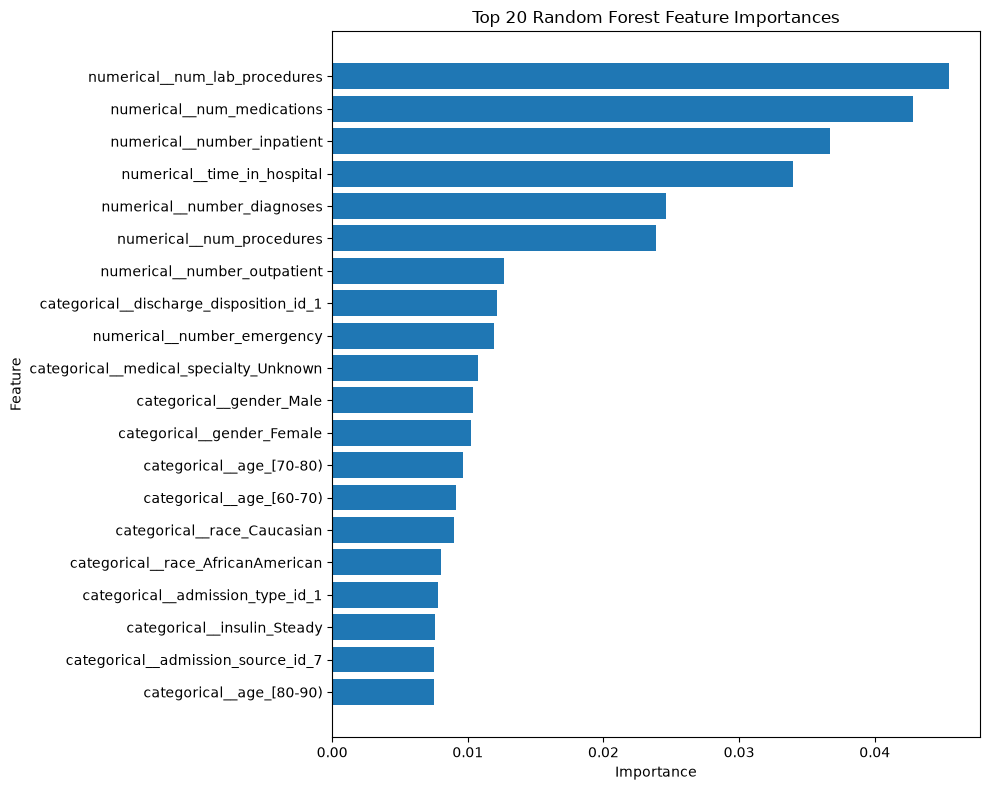

In [39]:
# Get the trained Random Forest 
rf = model.named_steps['classifier']

# Get feature names 
feature_names = model.named_steps['preprocessor'].get_feature_names_out()

# Create a DataFrame of feature importances
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf.feature_importances_
})

# Get the Top 20
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
).head(20)


plt.figure(figsize=(10, 8))

plt.barh(
    importance_df['Feature'][::-1],
    importance_df['Importance'][::-1]
)

plt.title('Top 20 Random Forest Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

This last one, the most important features, could be interesting to put on the report. 